# How do the COE features relate to the movement of the average rent?

The 12 COE (Certificate of Entitlement) features are monthly: for each vehicle category the **number of bids received**, the **quota** (certificates on offer) and the **quota premium** (the price at which the quota cleared).
Category A is for cars up to 1,600 cc, B for cars above 1,600 cc, C for goods vehicles and buses, and E ("open") for any vehicle.
They are compared with the **average monthly rent** of the 39 train months (2021-01..2024-03; the validation and test months are not used).

The questions, in order:

1. **Do they move together?** The COE premiums and the rent over time (indexed to 2021-01 = 100).
2. **Is it the same trend, or do they move together month by month?** Correlation of the levels against the correlation of the monthly *changes*. Two series that both trend upward correlate strongly in levels whether or not one affects the other, so the changes are the fairer test.
3. **Does a COE change come before a rent change?** Correlation of the rent change with the COE change *k* months earlier, for k = 0..6.
4. **Would the COE features have helped to forecast the rent?** A forecast check against the rent's own time trend.

There are only 39 monthly points, so patterns of moderate size can arise by chance; the notebook says where that applies.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)


def find_root(start):
    """final_report: the folder that holds data/feature_config_static.py."""
    for folder in (start, *start.parents):
        if (folder / 'data' / 'feature_config_static.py').exists():
            return folder
    raise FileNotFoundError('final_report/data/feature_config_static.py not found above ' + str(start))


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))
from data.feature_config_static import LABEL                    # noqa: E402
from data.feature_config_temporal import COE_FEATURE          # noqa: E402

FINAL = ROOT / 'data' / 'features' / 'final'
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CATEGORY_COLOUR = {'A': BLUE, 'B': ORANGE, 'C': AQUA, 'E': YELLOW}
DIV = LinearSegmentedColormap.from_list('div_blue_red', ['#256abf', '#f0efec', '#e34948'])
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'normal',
                     'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
                     'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'font.size': 9.5, 'legend.frameon': False, 'lines.linewidth': 2})

# the monthly series of the 39 train months: COE features in their own units, and the mean rent of the rentals approved in the month
coe_all = pd.read_csv(FINAL / 'temporal_raw.csv')
coe_all['month'] = (coe_all['RENT_APPROVAL_YEAR'] - 2021) * 12 + coe_all['RENT_APPROVAL_MONTH'] - 1
coe = coe_all[coe_all['sample_type'] == 'train'].set_index('month')[COE_FEATURE]
static = pd.read_csv(FINAL / 'static_train_scaled.csv')
static['month'] = (static['RENT_APPROVAL_YEAR'] - 2021) * 12 + static['RENT_APPROVAL_MONTH'] - 1
rent = static[static['sample_type'] == 'train'].groupby('month')[LABEL].mean()
assert list(coe.index) == list(rent.index)
dates = pd.to_datetime([f'{2021 + m // 12}-{m % 12 + 1:02d}-01' for m in rent.index])

KIND = {'quota_premium': 'premium', 'quota': 'quota', 'bids_received': 'bids received'}
label = {c: f'{c.split("_")[1].upper()}: {KIND[c.split("_", 2)[2]]}' for c in COE_FEATURE}
print(f'{coe.shape[1]} COE features x {coe.shape[0]} months ({dates[0]:%Y-%m}..{dates[-1]:%Y-%m}); mean rent ${rent.iloc[0]:,.0f} -> ${rent.iloc[-1]:,.0f} ({rent.iloc[-1] / rent.iloc[0] - 1:+.0%})')
display(coe.describe().T[['min', '50%', 'max']].rename(index=label).round(0))

12 COE features x 39 months (2021-01..2024-03); mean rent $2,049 -> $3,097 (+51%)


,min,50%,max
A: bids received,617.0,862.0,1920.0
A: quota,460.0,618.0,964.0
A: premium,41500.0,77900.0,105000.0
B: bids received,500.0,818.0,1554.0
B: quota,409.0,554.0,1020.0
B: premium,46001.0,99669.0,148002.0
C: bids received,86.0,196.0,675.0
C: quota,46.0,104.0,376.0
C: premium,37001.0,57590.0,88245.0
E: bids received,210.0,283.0,732.0


## 1. Do they move together?

The monthly mean rent and the four COE premiums on one axis, each indexed to 2021-01 = 100 so that their movements can be compared.

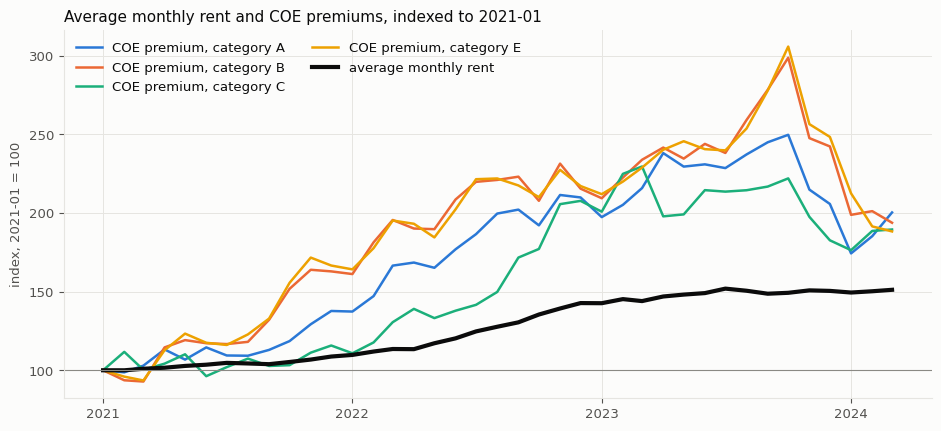

In [2]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
for cat, colour in CATEGORY_COLOUR.items():
    s = coe[f'coe_{cat.lower()}_quota_premium']
    ax.plot(dates, 100 * s / s.iloc[0], color=colour, lw=1.8, label=f'COE premium, category {cat}')
ax.plot(dates, 100 * rent / rent.iloc[0], color=INK, lw=3, label='average monthly rent')
ax.axhline(100, color=MUTED, lw=0.8)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylabel('index, 2021-01 = 100')
ax.set_title('Average monthly rent and COE premiums, indexed to 2021-01')
ax.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

## 2. The same trend, or the same movements?

For each COE feature, the Spearman correlation with the average monthly rent of the **levels** (n = 39) and of the **monthly changes** (n = 38).
The dashed lines mark the size of correlation that would be unusual by chance for 38 points (p < 0.05, not corrected for the 12 features).

,label,levels,changes,p_changes
feature,,,,
coe_e_quota,E: quota,-0.859,0.018,0.917
coe_e_bids_received,E: bids received,-0.679,-0.033,0.845
coe_b_quota,B: quota,-0.594,-0.184,0.269
coe_b_bids_received,B: bids received,-0.524,0.012,0.942
coe_c_bids_received,C: bids received,-0.374,-0.044,0.795
coe_c_quota,C: quota,-0.338,-0.040,0.810
coe_a_bids_received,A: bids received,-0.143,-0.071,0.672
coe_a_quota,A: quota,-0.105,-0.053,0.753
coe_e_quota_premium,E: premium,0.862,-0.002,0.990


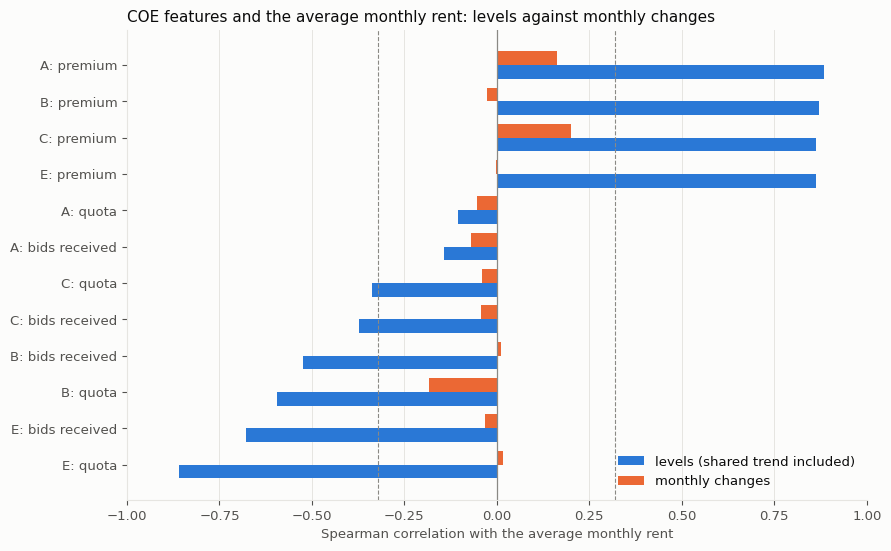

In [3]:
def corr_p(r, n):
    return 2 * stats.t.sf(abs(r) * np.sqrt((n - 2) / (1 - r ** 2)), n - 2)


def critical(n):
    t = stats.t.isf(0.025, n - 2)
    return t / np.sqrt(n - 2 + t ** 2)


rows = []
for c in COE_FEATURE:
    rows.append({'feature': c, 'label': label[c], 'levels': coe[c].corr(rent, method='spearman'), 'changes': coe[c].diff().corr(rent.diff(), method='spearman')})
corr = pd.DataFrame(rows).set_index('feature')
corr['p_changes'] = [corr_p(r, 38) for r in corr['changes']]
corr = corr.sort_values('levels')
display(corr[['label', 'levels', 'changes', 'p_changes']].round(3))

fig, ax = plt.subplots(figsize=(9, 5.6))
pos = np.arange(len(corr))
h = 0.38
ax.barh(pos - h / 2, corr['levels'], height=h, color=BLUE, label='levels (shared trend included)')
ax.barh(pos + h / 2, corr['changes'], height=h, color=ORANGE, label='monthly changes')
ax.axvline(0, color=MUTED, lw=0.9)
for sign in (-1, 1):
    ax.axvline(sign * critical(38), color=MUTED, lw=0.8, ls='--')
ax.set_yticks(pos, corr['label'])
ax.set_xlim(-1, 1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Spearman correlation with the average monthly rent')
ax.set_title('COE features and the average monthly rent: levels against monthly changes')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 3. Does a COE change come before a rent change?

The correlation between the change of the rent in month *t* and the change of the COE feature in month *t - k*, for k = 0 (same month) to 6. A strong value at k = 3 would mean that COE movements are followed by rent movements three months later.
Cells with a bold outline have p < 0.05 **without correcting for the 84 correlations in the chart**: about four of them are expected to reach that by chance alone.

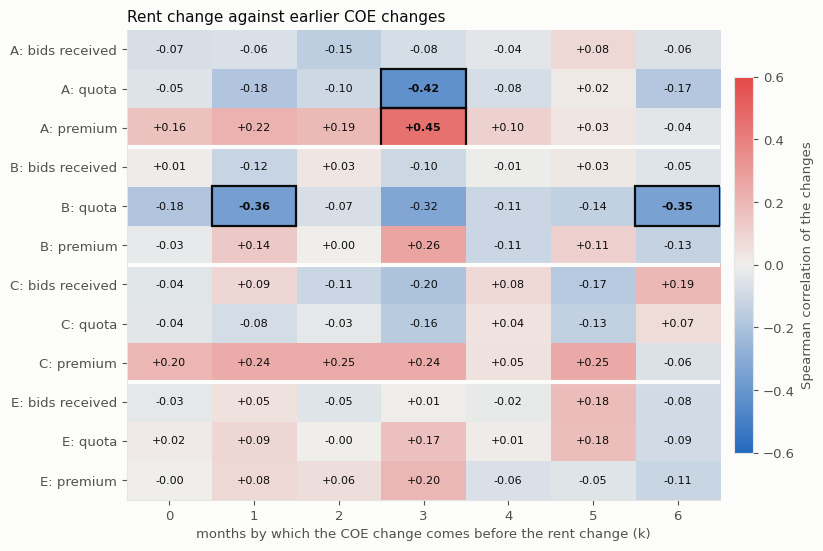

4 of 84 correlations have p < 0.05 (about 4 expected by chance); the strongest is ('coe_a_quota_premium', 3) with +0.45


In [4]:
LAGS = range(0, 7)
order = [c for cat in 'ABCE' for c in COE_FEATURE if c.split('_')[1] == cat.lower()]
lag_corr = pd.DataFrame({k: {c: coe[c].diff().shift(k).corr(rent.diff(), method='spearman') for c in order} for k in LAGS})
lag_n = {k: int((coe[order[0]].diff().shift(k).notna() & rent.diff().notna()).sum()) for k in LAGS}
lag_p = pd.DataFrame({k: [corr_p(r, lag_n[k]) for r in lag_corr[k]] for k in LAGS}, index=order)

fig, ax = plt.subplots(figsize=(8.6, 5.6))
im = ax.imshow(lag_corr.to_numpy(), cmap=DIV, vmin=-0.6, vmax=0.6, aspect='auto')
ax.set_xticks(range(len(LAGS)), [f'{k}' for k in LAGS])
ax.set_yticks(range(len(order)), [label[c] for c in order])
ax.set_xlabel('months by which the COE change comes before the rent change (k)')
ax.grid(False)
for i, c in enumerate(order):
    for j, k in enumerate(LAGS):
        significant = lag_p.loc[c, k] < 0.05
        ax.text(j, i, f'{lag_corr.loc[c, k]:+.2f}', ha='center', va='center', fontsize=8, color=INK, fontweight='bold' if significant else 'normal')
        if significant:
            ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=1.6))
for y in (2.5, 5.5, 8.5):
    ax.axhline(y, color=SURFACE, lw=3)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.set_label('Spearman correlation of the changes')
ax.set_title('Rent change against earlier COE changes')
plt.tight_layout()
plt.show()
print(f'{int((lag_p.to_numpy() < 0.05).sum())} of {lag_p.size} correlations have p < 0.05 (about {0.05 * lag_p.size:.0f} expected by chance); the strongest is {lag_corr.stack().abs().idxmax()} with {lag_corr.stack()[lag_corr.stack().abs().idxmax()]:+.2f}')

## 4. Would the COE features have helped to forecast the rent?

For each COE feature a line `rent = a + b x feature` is fitted on the months before a forecast origin and used to forecast the next six months from the feature values of those months (origins at months 21, 27 and 33).
The skill compares it with forecasting the rent by the straight-line trend of its own history: **above 0 the COE feature beats the trend**, 1 is a perfect forecast, and a negative value means the trend alone does better.

In [5]:
ORIGINS, HORIZON = (21, 27, 33), 6


def ols_forecast(X_tr, y_tr, X_te):
    mx, my = X_tr.mean(axis=0), y_tr.mean()
    var = ((X_tr - mx) ** 2).sum(axis=0)
    slope = np.divide(((X_tr - mx) * (y_tr - my)[:, None]).sum(axis=0), var, out=np.zeros_like(var), where=var > 0)
    return my + (X_te - mx) * slope


X, y, t = coe.to_numpy(float), rent.to_numpy(), np.arange(len(rent), dtype=float)[:, None]
sse_model, sse_trend, sse_carry = np.zeros(X.shape[1]), 0.0, 0.0
for k in ORIGINS:
    tr, te = slice(0, k), slice(k, k + HORIZON)
    sse_model += ((ols_forecast(X[tr], y[tr], X[te]) - y[te][:, None]) ** 2).sum(axis=0)
    sse_trend += ((ols_forecast(t[tr], y[tr], t[te]) - y[te][:, None]) ** 2).sum()
    sse_carry += ((y[k - 1] - y[te]) ** 2).sum()
n_test = len(ORIGINS) * HORIZON
skill = pd.DataFrame({'label': [label[c] for c in COE_FEATURE], 'rmse': np.sqrt(sse_model / n_test), 'skill_vs_trend': 1 - sse_model / sse_trend}, index=COE_FEATURE).sort_values('skill_vs_trend', ascending=False)
print(f'forecast RMSE over {n_test} test months: time trend ${np.sqrt(sse_trend / n_test):,.0f}, carry the last month forward ${np.sqrt(sse_carry / n_test):,.0f}')
display(skill.round(2))

forecast RMSE over 18 test months: time trend $195, carry the last month forward $152


,label,rmse,skill_vs_trend
coe_c_quota_premium,C: premium,198.53,-0.03
coe_a_quota_premium,A: premium,258.67,-0.75
coe_b_quota_premium,B: premium,329.93,-1.85
coe_e_quota_premium,E: premium,331.30,-1.88
coe_e_quota,E: quota,458.95,-4.52
coe_b_quota,B: quota,481.52,-5.07
coe_e_bids_received,E: bids received,505.97,-5.71
coe_b_bids_received,B: bids received,554.64,-7.06
coe_c_bids_received,C: bids received,606.30,-8.63
coe_c_quota,C: quota,621.00,-9.10


# Findings

From the run stored in this notebook (39 train months, 2021-01..2024-03).

* **They moved together over the period.** The average rent rose 51% ($2,049 to $3,097). The COE premiums rose faster, to about 2.2-3.1 times their January 2021 level by mid-2023, then fell back to about 1.9-2.0 times while the rent levelled off at about 1.5 times. The Spearman correlation of the levels is +0.86 to +0.88 for the four premiums, and negative for the quotas and bids of categories B, C and E (e.g. E quota -0.86, B quota -0.59); category A's quota and bids are nearly unrelated (about -0.1).
* **Month by month they do not.** The correlations of the monthly *changes* are all small: between -0.18 and +0.20, with p >= 0.22 for every one of the 12 features. The high correlation of the levels is therefore the shared trend of 2021-2023, which would appear whether or not the COE affected rents: both series were pushed up by the same post-pandemic conditions.
* **The lead-lag chart gives no robust lead.** 4 of the 84 correlations are significant at 5%, which is the number expected by chance. The strongest are category A at a three-month lag: a rise of the A premium is followed by a rise of the rent three months later (+0.45), and a fall of the A quota likewise (-0.42). Both fit one story and are worth a look in new data, but with 84 comparisons and 36 months they are not established.
* **The COE features did not forecast the rent better than its own trend.** Over 18 forecast months the straight-line trend has an RMSE of $195 and carrying the last month forward $152. The best COE feature, the C premium, gets $199 (skill -0.03, about the same as the trend); the A premium $259, B and E premiums about $330, and the quotas and bids between $460 and $890.

**What can be said.** The COE premiums and the average rent rose and fell on a similar path, but nothing in these 39 months shows that COE movements drive rent movements: the changes are unrelated, only a weak, unconfirmed three-month lead exists for category A, and the features do not improve a forecast over the trend. In the models they are best read as stand-ins for the period's general economic conditions.
The average rent also mixes flat types and locations, which change from month to month, so a small effect on rents could be hidden in it; 39 months cannot rule one out.